In [4]:
import mne
mne.viz.set_browser_backend("matplotlib")

sample_dir = mne.datasets.sample.data_path() / "MEG" / "sample"
raw = mne.io.read_raw_fif(sample_dir / "sample_audvis_raw.fif")
print(raw)

Using matplotlib as 2D backend.
Opening raw data file /Users/marcocurran/Downloads/VS Code Profiles/thesis/Masters-Thesis-5th-Year/mne-learning/data/MNE-sample-data/MEG/sample/sample_audvis_raw.fif...


/Users/marcocurran/Downloads/VS Code Profiles/thesis/Masters-Thesis-5th-Year/mne-learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
<Raw | sample_audvis_raw.fif, 376 x 166800 (277.7 s), ~3.2 MiB, data not loaded>


In [5]:
print(raw.info)
print("Sampling rate:", raw.info["sfreq"])
print("Bad channels:", raw.info["bads"])
print("First 10 channels:", raw.ch_names[:10])

<Info | 21 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: acquisition (megacq) VectorView system at NMR-MGH
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: MEG
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 lowpass: 172.2 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 1
 proj_name: test
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
>
Sampling rate: 600.614990234375
Bad channels: ['MEG 2443', 'EEG 053']
First 10 channels: ['MEG 0113', 'MEG 0112', 'MEG 0111', 'MEG 0122', 'MEG 0123', 'MEG 0121', 'MEG 0132', 'MEG 0133', 'MEG 0131', '

In [6]:
print(raw.get_channel_types(unique=True))

from collections import Counter
print(Counter(raw.get_channel_types()))

['grad', 'mag', 'stim', 'eeg', 'eog']
Counter({'grad': 204, 'mag': 102, 'eeg': 60, 'stim': 9, 'eog': 1})


In [7]:
eeg = raw.copy().pick("eeg").load_data()
data, times = eeg.get_data(return_times=True, tmin=0, tmax=5)
print("Shape:", data.shape)
print("Units: volts. First value in µV:", data[0, 0] * 1e6)

Reading 0 ... 166799  =      0.000 ...   277.714 secs...
Shape: (60, 3003)
Units: volts. First value in µV: 11.398925963135298


In [8]:
print("First sample index:", raw.first_samp)
print("Duration (s):", raw.times[-1])

First sample index: 25800
Duration (s): 277.7136813300495


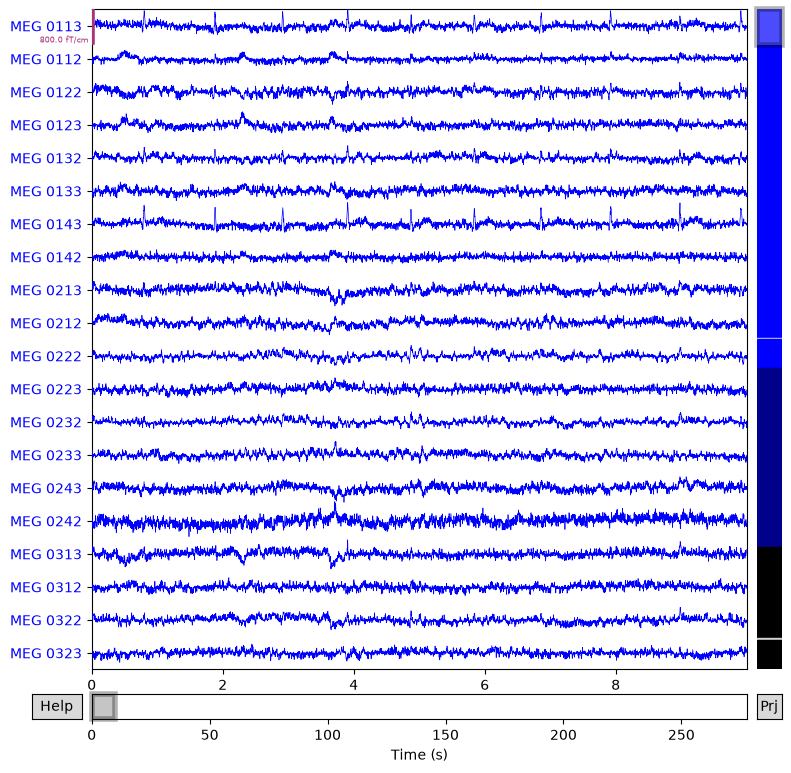

Effective window size : 3.410 (s)
Plotting power spectral density (dB=True).


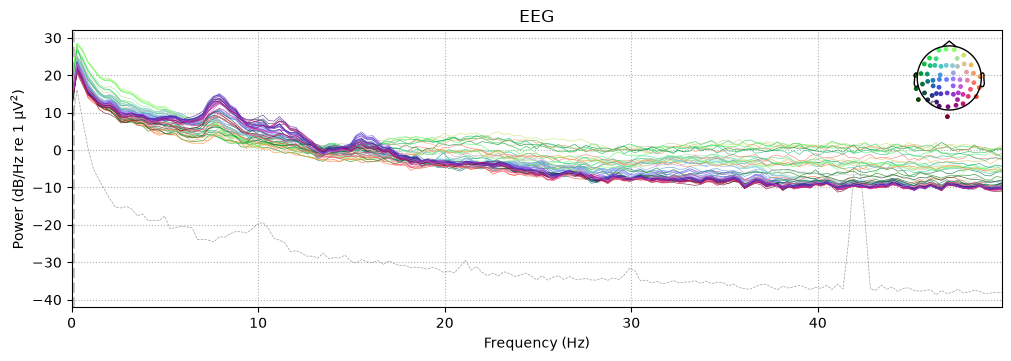

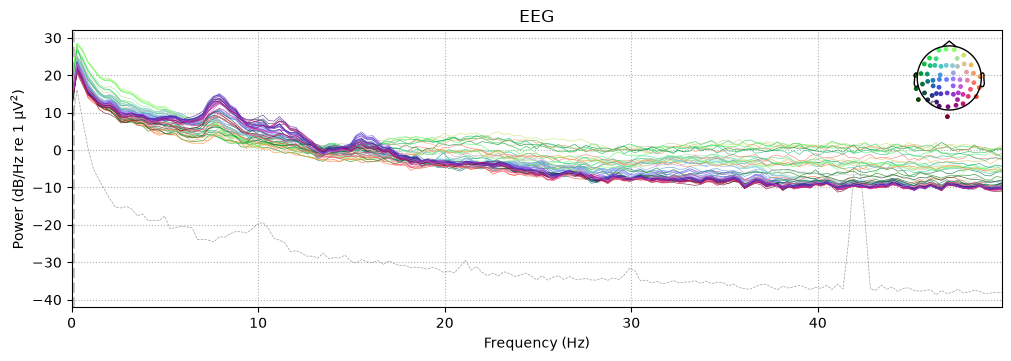

In [9]:
raw.plot(duration=10, n_channels=20)
eeg.compute_psd(fmax=50).plot()

Creating RawArray with float64 data, n_channels=4, n_times=1000
    Range : 0 ... 999 =      0.000 ...     9.990 secs
Ready.
<RawArray | 4 x 1000 (10.0 s), ~38 KiB, data loaded>


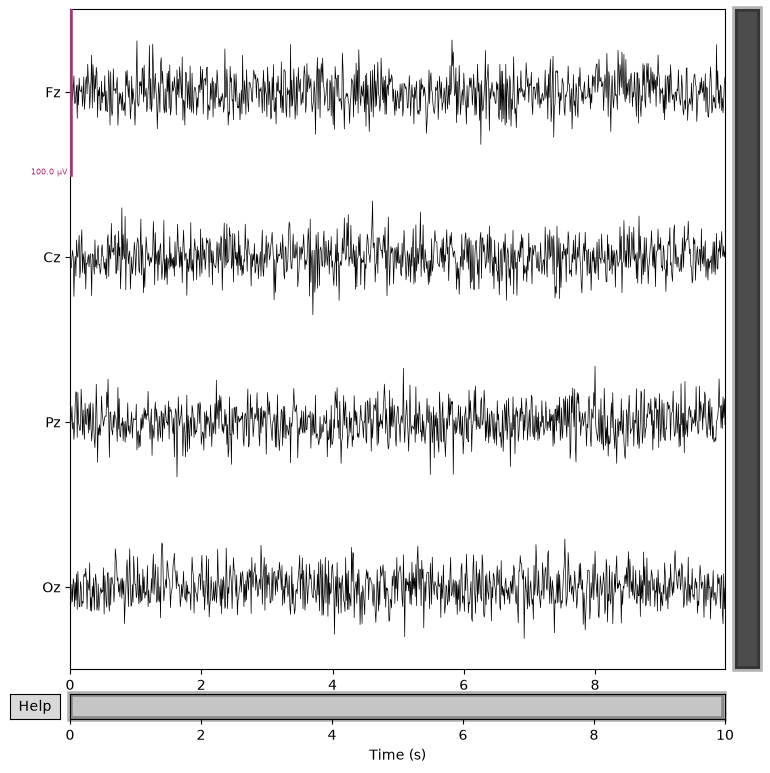

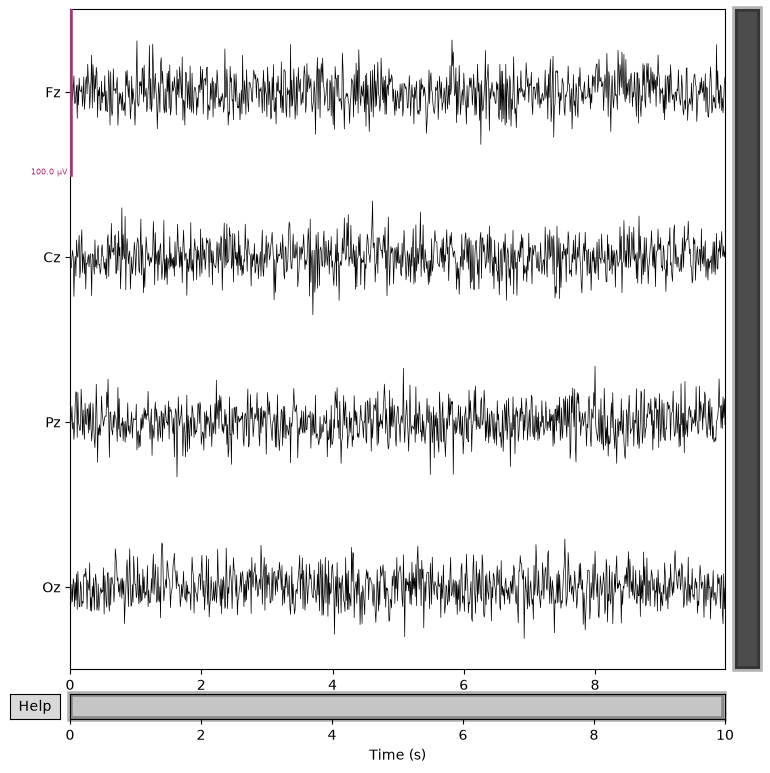

In [10]:
import numpy as np

# Pretend this is one CND trial: 1000 samples × 4 channels, in µV
cnd_trial = np.random.randn(1000, 4) * 10
fs = 100.0
labels = ["Fz", "Cz", "Pz", "Oz"]

info = mne.create_info(ch_names=labels, sfreq=fs, ch_types="eeg")
fake_raw = mne.io.RawArray(cnd_trial.T * 1e-6, info)   # transpose + µV → V

print(fake_raw)
fake_raw.plot(scalings=dict(eeg=50e-6))

In [11]:
def raw_to_cnd_trial(raw, unit="uV"):
    scale = {"V": 1, "uV": 1e6}[unit]
    return raw.get_data().T * scale    # back to samples × channels

back = raw_to_cnd_trial(fake_raw)
print(np.allclose(back, cnd_trial))    # should print True

True
